# E-commerce AI Customer Support
## Data Validation & Exploratory Data Analysis

### Objective

This notebook validates and explores the datasets used for the
AI-powered multi-agent customer support system.

Datasets:
- FAQ Knowledge Base
- Customer Support Tickets

The analysis covers:
- Data structure
- Data types
- Missing values
- Duplicate records
- Label distributions
- Ticket characteristics
- Resolution statistics
- Escalation patterns
- Data quality issues

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 120)

In [2]:
FAQ_PATH = "../data/raw/faq_knowledge_base_150.csv"
TICKETS_PATH = "../data/raw/support_tickets.csv"

In [3]:
print("Checking dataset files...\n")

print("FAQ file exists     :", os.path.exists(FAQ_PATH))
print("Tickets file exists :", os.path.exists(TICKETS_PATH))

Checking dataset files...

FAQ file exists     : True
Tickets file exists : True


In [4]:
faq_df = pd.read_csv(FAQ_PATH)
tickets_df = pd.read_csv(TICKETS_PATH)

print("Datasets loaded successfully.")

Datasets loaded successfully.


In [5]:
print("FAQ Dataset Shape    :", faq_df.shape)
print("Tickets Dataset Shape:", tickets_df.shape)

FAQ Dataset Shape    : (150, 4)
Tickets Dataset Shape: (10000, 15)


In [6]:
faq_df.head()

,faq_id,question,answer,category
0,FAQ001,How do I track my order?,Go to My Orders > Select Order > Track Package for real-time courier updates.,Delivery Issue
1,FAQ002,What should I do if my order is delayed?,"Check tracking first. If no update for 48 hours, raise a complaint via My Orders > Help.",Delivery Issue
2,FAQ003,Can I change my delivery address after placing an order?,"Yes, before dispatch. Go to My Orders > Order Details > Edit Address.",Delivery Issue
3,FAQ004,What happens if I miss my delivery?,Courier will reattempt delivery. You can also reschedule via the tracking link.,Delivery Issue
4,FAQ005,How do I reschedule my delivery?,Use the tracking link in your SMS/email to select a new delivery slot.,Delivery Issue


In [7]:
tickets_df.head()

,ticket_id,created_date,ticket_text,product_name,product_segment,ticket_category,priority,sentiment,confidence_score,escalated,resolution_text,resolved_date,resolution_days,auto_resolved,customer_satisfaction_score
0,TKT100000,2023-08-12,The lipstick I received in order #ORD5614226 stopped working after just 5 days of use.,lipstick,Beauty & Personal Care,Product Issue,High,Negative,0.66,Yes,Full refund processed. Seller account flagged for quality investigation.,2023-08-14,2,No,1
1,TKT100001,2023-12-11,The shoe rack received in order #ORD8038374 has scratches and dents. Looks like a returned/used ...,shoe rack,Home & Kitchen,Product Issue,High,Negative,0.74,Yes,Missing accessory shipped separately at no additional cost.,2023-12-12,1,No,1
2,TKT100002,2024-01-06,I want to exchange my conditioner (order #ORD6770619) for a different size. Exchange option is m...,conditioner,Beauty & Personal Care,Refund & Return,Low,Positive,0.93,No,Accidental order refund approved. Amount credited within 2 days.,2024-01-16,10,Yes,4
3,TKT100003,2024-11-17,My makeup brush set from order #ORD4823498 appears to be counterfeit/fake. Not the original brand.,makeup brush set,Beauty & Personal Care,Product Issue,High,Very Negative,0.78,Yes,Missing accessory shipped separately at no additional cost.,2024-11-20,3,No,1
4,TKT100004,2023-08-23,Product listing for lipstick is completely misleading. The actual product is nothing like the ph...,lipstick,Beauty & Personal Care,Product Issue,Medium,Neutral,0.94,No,Replacement lipstick dispatched after quality team verification.,2023-08-24,1,No,4


In [8]:
print("FAQ Columns:")
for col in faq_df.columns:
    print("-", col)

print("\nTicket Columns:")
for col in tickets_df.columns:
    print("-", col)

FAQ Columns:
- faq_id
- question
- answer
- category

Ticket Columns:
- ticket_id
- created_date
- ticket_text
- product_name
- product_segment
- ticket_category
- priority
- sentiment
- confidence_score
- escalated
- resolution_text
- resolved_date
- resolution_days
- auto_resolved
- customer_satisfaction_score


In [9]:
print("FAQ Data Types")
display(faq_df.dtypes)

print("\nTicket Data Types")
display(tickets_df.dtypes)

FAQ Data Types


faq_id      str
question    str
answer      str
category    str
dtype: object


Ticket Data Types


ticket_id                          str
created_date                       str
ticket_text                        str
product_name                       str
product_segment                    str
ticket_category                    str
priority                           str
sentiment                          str
confidence_score               float64
escalated                          str
resolution_text                    str
resolved_date                      str
resolution_days                  int64
auto_resolved                      str
customer_satisfaction_score      int64
dtype: object

In [10]:
print("FAQ Information")
faq_df.info()

print("\n" + "=" * 80 + "\n")

print("Ticket Information")
tickets_df.info()

FAQ Information
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   faq_id    150 non-null    str  
 1   question  150 non-null    str  
 2   answer    150 non-null    str  
 3   category  150 non-null    str  
dtypes: str(4)
memory usage: 4.8 KB


Ticket Information
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ticket_id                    10000 non-null  str    
 1   created_date                 10000 non-null  str    
 2   ticket_text                  10000 non-null  str    
 3   product_name                 10000 non-null  str    
 4   product_segment              10000 non-null  str    
 5   ticket_category              10000 non-null  str    
 6   priority                     10000 non-null  s

In [11]:
faq_missing = faq_df.isnull().sum()
ticket_missing = tickets_df.isnull().sum()

print("FAQ Missing Values")
display(faq_missing[faq_missing > 0])

print("\nTicket Missing Values")
display(ticket_missing[ticket_missing > 0])

FAQ Missing Values


Series([], dtype: int64)


Ticket Missing Values


Series([], dtype: int64)

In [12]:
faq_missing_pct = (
    faq_df.isnull().mean() * 100
).sort_values(ascending=False)

ticket_missing_pct = (
    tickets_df.isnull().mean() * 100
).sort_values(ascending=False)

print("FAQ Missing Percentage")
display(faq_missing_pct[faq_missing_pct > 0])

print("\nTicket Missing Percentage")
display(ticket_missing_pct[ticket_missing_pct > 0])

FAQ Missing Percentage


Series([], dtype: float64)


Ticket Missing Percentage


Series([], dtype: float64)

In [13]:
print("FAQ duplicate rows     :", faq_df.duplicated().sum())
print("Ticket duplicate rows  :", tickets_df.duplicated().sum())

FAQ duplicate rows     : 0
Ticket duplicate rows  : 0


In [14]:
print("Duplicate FAQ IDs:")
print(faq_df["faq_id"].duplicated().sum())

print("\nDuplicate Ticket IDs:")
print(tickets_df["ticket_id"].duplicated().sum())

Duplicate FAQ IDs:
0

Duplicate Ticket IDs:
0


In [15]:
print("Ticket Categories:")
print(tickets_df["ticket_category"].unique())

print("\nNumber of Categories:")
print(tickets_df["ticket_category"].nunique())

Ticket Categories:
<StringArray>
[           'Product Issue',          'Refund & Return',            'Payment Issue', 'Seller & Product Listing',
      'App & Website Issue',           'Delivery Issue',          'Account & Login']
Length: 7, dtype: str

Number of Categories:
7


In [16]:
category_counts = (
    tickets_df["ticket_category"]
    .value_counts()
    .sort_values(ascending=False)
)

display(category_counts)

ticket_category
Refund & Return             2051
Delivery Issue              1950
Product Issue               1948
Payment Issue               1474
Account & Login             1030
Seller & Product Listing     830
App & Website Issue          717
Name: count, dtype: int64

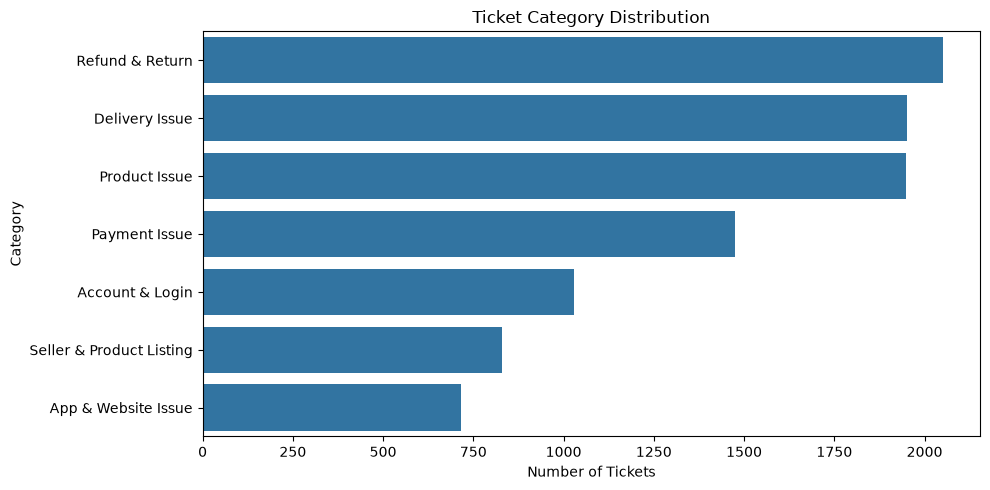

In [22]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=tickets_df,
    y="ticket_category",
    order=tickets_df["ticket_category"].value_counts().index
)

plt.title("Ticket Category Distribution")
plt.xlabel("Number of Tickets")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [17]:
print("Priority Distribution:")
display(tickets_df["priority"].value_counts())

Priority Distribution:


priority
High      4620
Medium    3657
Low       1723
Name: count, dtype: int64

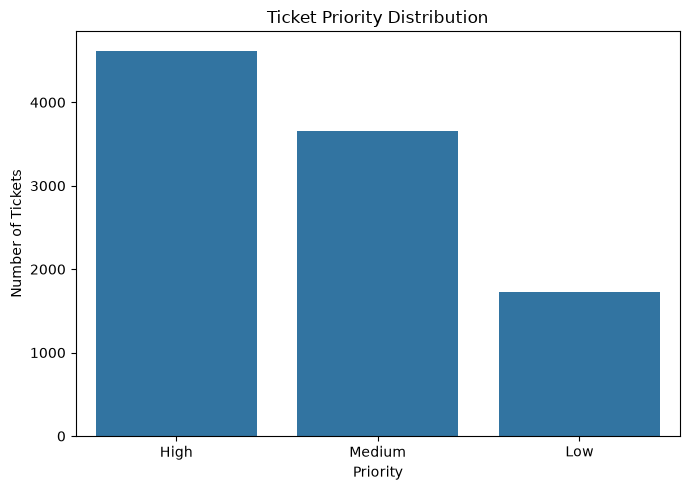

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=tickets_df,
    x="priority",
    order=tickets_df["priority"].value_counts().index
)

plt.title("Ticket Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

In [18]:
print("Sentiment Distribution:")
display(tickets_df["sentiment"].value_counts())

Sentiment Distribution:


sentiment
Negative             3077
Neutral              2732
Slightly Negative    1800
Very Negative        1543
Positive              848
Name: count, dtype: int64

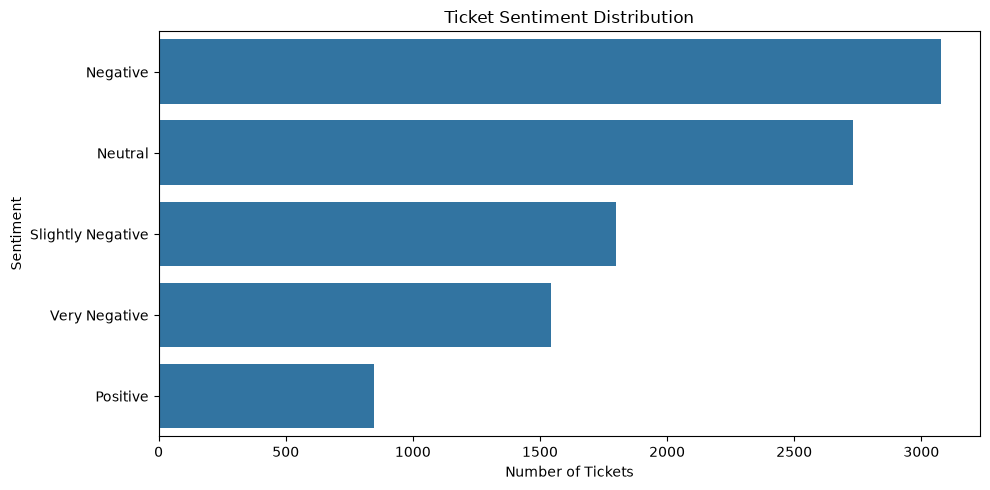

In [24]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=tickets_df,
    y="sentiment",
    order=tickets_df["sentiment"].value_counts().index
)

plt.title("Ticket Sentiment Distribution")
plt.xlabel("Number of Tickets")
plt.ylabel("Sentiment")
plt.tight_layout()
plt.show()

In [19]:
print("Escalation Distribution:")
display(tickets_df["escalated"].value_counts())

Escalation Distribution:


escalated
No     6622
Yes    3378
Name: count, dtype: int64

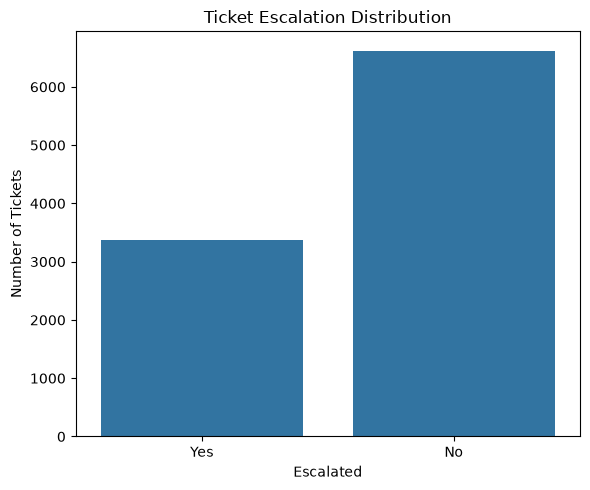

In [25]:
plt.figure(figsize=(6, 5))

sns.countplot(
    data=tickets_df,
    x="escalated"
)

plt.title("Ticket Escalation Distribution")
plt.xlabel("Escalated")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

In [20]:
print("Auto-Resolution Distribution:")
display(tickets_df["auto_resolved"].value_counts())

Auto-Resolution Distribution:


auto_resolved
No     9304
Yes     696
Name: count, dtype: int64

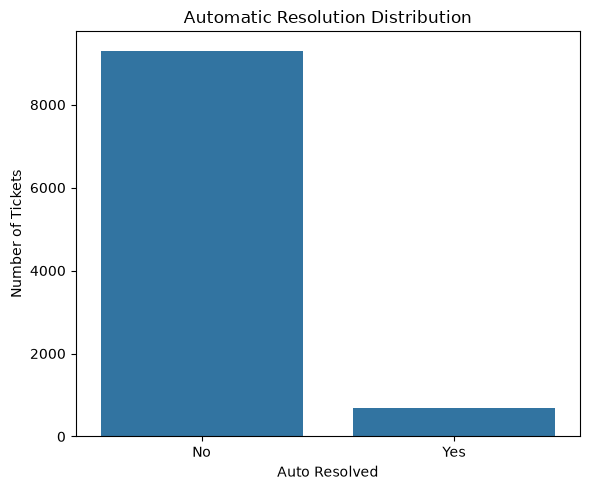

In [26]:
plt.figure(figsize=(6, 5))

sns.countplot(
    data=tickets_df,
    x="auto_resolved"
)

plt.title("Automatic Resolution Distribution")
plt.xlabel("Auto Resolved")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

In [21]:
print("Customer Satisfaction Distribution:")

display(
    tickets_df["customer_satisfaction_score"]
    .value_counts()
    .sort_index()
)

Customer Satisfaction Distribution:


customer_satisfaction_score
1    1193
2    1123
3    2298
4    3264
5    2122
Name: count, dtype: int64

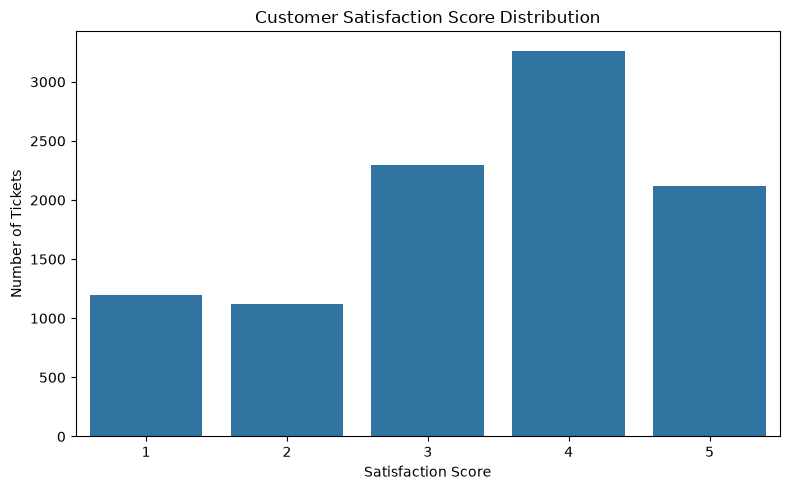

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=tickets_df,
    x="customer_satisfaction_score"
)

plt.title("Customer Satisfaction Score Distribution")
plt.xlabel("Satisfaction Score")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

In [28]:
tickets_df["confidence_score"].describe()

count    10000.000000
mean         0.818234
std          0.098229
min          0.650000
25%          0.730000
50%          0.820000
75%          0.900000
max          0.990000
Name: confidence_score, dtype: float64

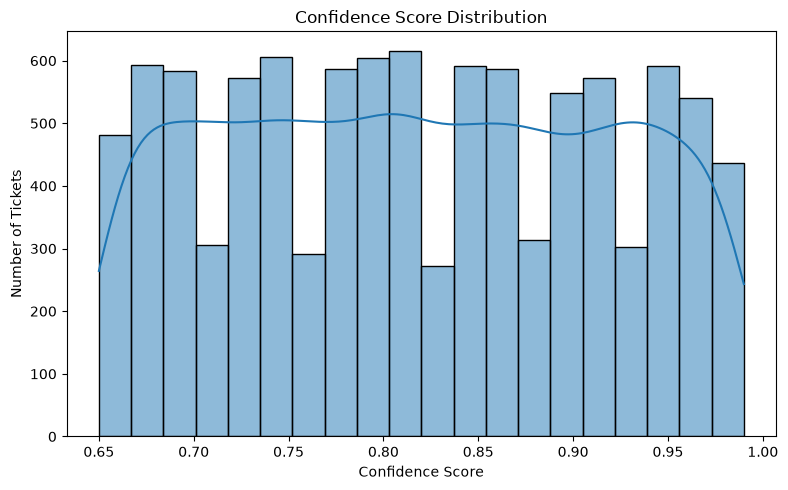

In [29]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=tickets_df,
    x="confidence_score",
    bins=20,
    kde=True
)

plt.title("Confidence Score Distribution")
plt.xlabel("Confidence Score")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

In [30]:
tickets_df["resolution_days"].describe()

count    10000.000000
mean         4.815200
std          2.615709
min          1.000000
25%          3.000000
50%          5.000000
75%          7.000000
max         10.000000
Name: resolution_days, dtype: float64

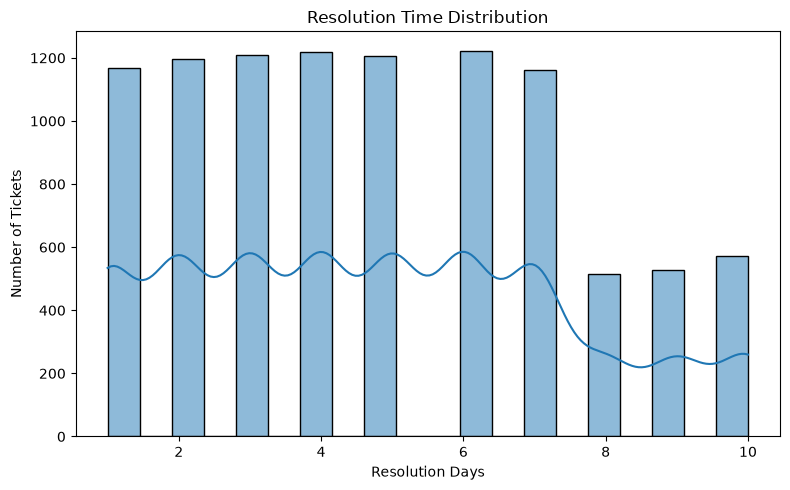

In [31]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=tickets_df,
    x="resolution_days",
    bins=20,
    kde=True
)

plt.title("Resolution Time Distribution")
plt.xlabel("Resolution Days")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

In [32]:
print("Number of Product Segments:")
print(tickets_df["product_segment"].nunique())

print("\nProduct Segment Distribution:")
display(tickets_df["product_segment"].value_counts())

Number of Product Segments:
8

Product Segment Distribution:


product_segment
Electronics               1573
Beauty & Personal Care    1560
Home & Kitchen            1524
Fashion                   1501
Sports & Fitness          1181
Grocery & Health          1158
Toys & Games               784
Books & Education          719
Name: count, dtype: int64

In [33]:
print("Top 20 Products by Ticket Count:")

display(
    tickets_df["product_name"]
    .value_counts()
    .head(20)
)

Top 20 Products by Ticket Count:


product_name
lipstick              97
soft toy              96
atta (wheat flour)    93
yoga mat              92
bluetooth speaker     92
jump rope             91
makeup brush set      90
perfume               90
gaming console        90
storage rack          90
badminton racket      90
pressure cooker       90
bedsheet set          89
robot vacuum          88
smartwatch            88
beard trimmer         87
body lotion           87
breakfast cereal      87
board game            87
running shoes         86
Name: count, dtype: int64

In [34]:
category_priority = pd.crosstab(
    tickets_df["ticket_category"],
    tickets_df["priority"]
)

display(category_priority)

priority,High,Low,Medium
ticket_category,,,
Account & Login,286,306,438
App & Website Issue,31,418,268
Delivery Issue,1009,165,776
Payment Issue,729,240,505
Product Issue,1110,177,661
Refund & Return,996,382,673
Seller & Product Listing,459,35,336


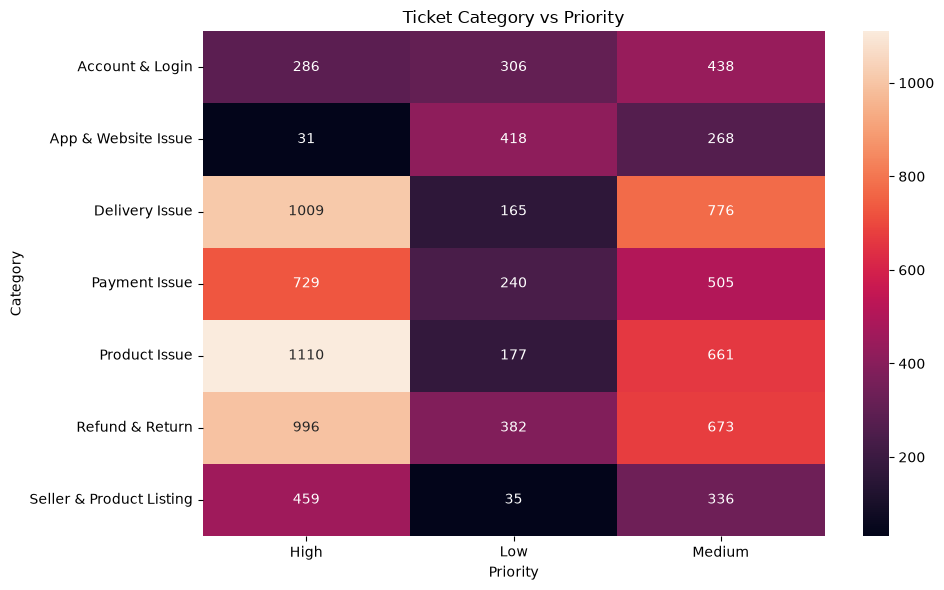

In [35]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    category_priority,
    annot=True,
    fmt="d"
)

plt.title("Ticket Category vs Priority")
plt.xlabel("Priority")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [36]:
category_sentiment = pd.crosstab(
    tickets_df["ticket_category"],
    tickets_df["sentiment"]
)

display(category_sentiment)

sentiment,Negative,Neutral,Positive,Slightly Negative,Very Negative
ticket_category,,,,,
Account & Login,189,372,152,220,97
App & Website Issue,15,347,204,135,16
Delivery Issue,664,492,87,362,345
Payment Issue,514,355,113,277,215
Product Issue,718,448,82,308,392
Refund & Return,659,533,192,330,337
Seller & Product Listing,318,185,18,168,141


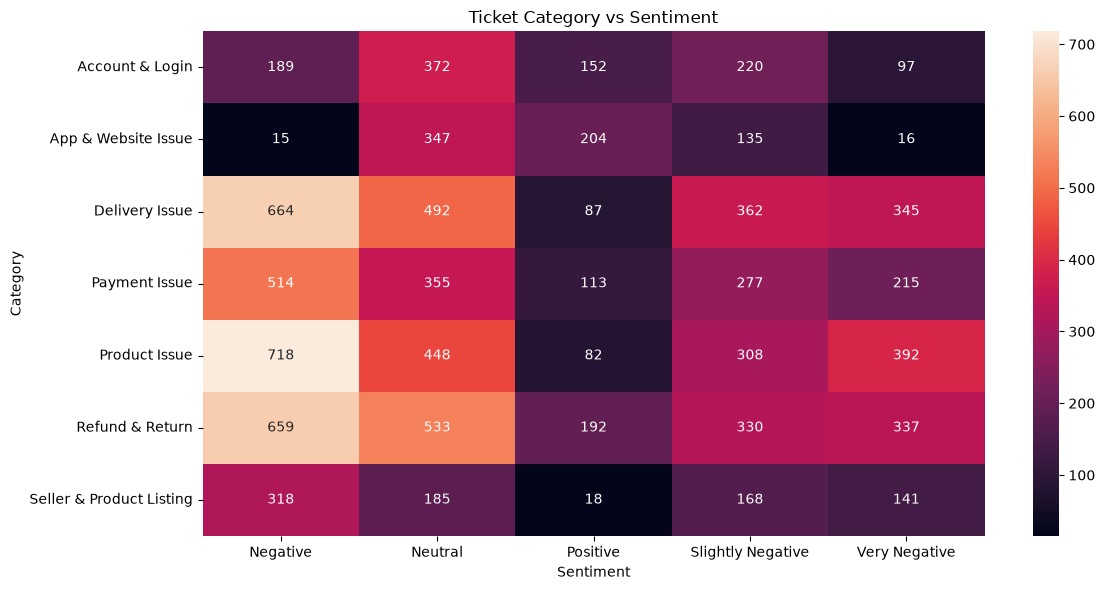

In [37]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    category_sentiment,
    annot=True,
    fmt="d"
)

plt.title("Ticket Category vs Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [38]:
category_escalation = pd.crosstab(
    tickets_df["ticket_category"],
    tickets_df["escalated"]
)

display(category_escalation)

escalated,No,Yes
ticket_category,,
Account & Login,839,191
App & Website Issue,692,25
Delivery Issue,1210,740
Payment Issue,941,533
Product Issue,1151,797
Refund & Return,1305,746
Seller & Product Listing,484,346


In [39]:
priority_escalation = pd.crosstab(
    tickets_df["priority"],
    tickets_df["escalated"]
)

display(priority_escalation)

escalated,No,Yes
priority,,
High,1242,3378
Low,1723,0
Medium,3657,0


In [40]:
auto_resolution_satisfaction = (
    tickets_df
    .groupby("auto_resolved")["customer_satisfaction_score"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(auto_resolution_satisfaction)

,count,mean,median
auto_resolved,,,
No,9304,3.32,4.0
Yes,696,4.51,5.0


In [41]:
escalation_satisfaction = (
    tickets_df
    .groupby("escalated")["customer_satisfaction_score"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(escalation_satisfaction)

,count,mean,median
escalated,,,
No,6622,3.87,4.0
Yes,3378,2.48,2.0


In [42]:
resolution_by_category = (
    tickets_df
    .groupby("ticket_category")["resolution_days"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
    .round(2)
)

display(resolution_by_category)

,count,mean,median,min,max
ticket_category,,,,,
App & Website Issue,717,5.48,5.0,1,10
Account & Login,1030,4.88,5.0,1,10
Payment Issue,1474,4.83,5.0,1,10
Refund & Return,2051,4.78,5.0,1,10
Delivery Issue,1950,4.78,5.0,1,10
Seller & Product Listing,830,4.75,5.0,1,10
Product Issue,1948,4.62,4.0,1,10


In [43]:
resolution_by_priority = (
    tickets_df
    .groupby("priority")["resolution_days"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
    .round(2)
)

display(resolution_by_priority)

,count,mean,median,min,max
priority,,,,,
Low,1723,5.54,6.0,1,10
Medium,3657,5.47,5.0,1,10
High,4620,4.03,4.0,1,7


In [44]:
tickets_df["created_date"] = pd.to_datetime(
    tickets_df["created_date"],
    dayfirst=True,
    errors="coerce"
)

tickets_df["resolved_date"] = pd.to_datetime(
    tickets_df["resolved_date"],
    dayfirst=True,
    errors="coerce"
)

print(tickets_df[["created_date", "resolved_date"]].dtypes)

created_date     datetime64[us]
resolved_date    datetime64[us]
dtype: object


In [45]:
print("Invalid created dates:",
      tickets_df["created_date"].isna().sum())

print("Invalid resolved dates:",
      tickets_df["resolved_date"].isna().sum())

Invalid created dates: 6096
Invalid resolved dates: 0


In [46]:
invalid_resolution_dates = tickets_df[
    tickets_df["resolved_date"] < tickets_df["created_date"]
]

print(
    "Records where resolved_date is before created_date:",
    len(invalid_resolution_dates)
)

Records where resolved_date is before created_date: 1739


In [47]:
tickets_df["calculated_resolution_days"] = (
    tickets_df["resolved_date"] -
    tickets_df["created_date"]
).dt.days

In [48]:
resolution_check = tickets_df[
    tickets_df["calculated_resolution_days"]
    != tickets_df["resolution_days"]
]

print(
    "Records where calculated and supplied resolution days differ:",
    len(resolution_check)
)

Records where calculated and supplied resolution days differ: 9672


In [49]:
invalid_confidence = tickets_df[
    (tickets_df["confidence_score"] < 0) |
    (tickets_df["confidence_score"] > 1)
]

print(
    "Invalid confidence scores:",
    len(invalid_confidence)
)

Invalid confidence scores: 0


In [50]:
invalid_satisfaction = tickets_df[
    (tickets_df["customer_satisfaction_score"] < 1) |
    (tickets_df["customer_satisfaction_score"] > 5)
]

print(
    "Invalid satisfaction scores:",
    len(invalid_satisfaction)
)

Invalid satisfaction scores: 0


In [51]:
empty_ticket_text = tickets_df[
    tickets_df["ticket_text"].isna() |
    tickets_df["ticket_text"].str.strip().eq("")
]

print(
    "Empty ticket text records:",
    len(empty_ticket_text)
)

Empty ticket text records: 0


In [52]:
empty_faq_questions = faq_df[
    faq_df["question"].isna() |
    faq_df["question"].str.strip().eq("")
]

print(
    "Empty FAQ questions:",
    len(empty_faq_questions)
)

Empty FAQ questions: 0


In [53]:
tickets_df["ticket_text_length"] = (
    tickets_df["ticket_text"]
    .str.len()
)

tickets_df["ticket_word_count"] = (
    tickets_df["ticket_text"]
    .str.split()
    .str.len()
)

tickets_df[
    ["ticket_text_length", "ticket_word_count"]
].describe()

,ticket_text_length,ticket_word_count
count,10000.000000,10000.0000
mean,97.398100,15.9468
std,10.829577,1.9457
min,61.000000,11.0000
25%,90.000000,15.0000
50%,98.000000,16.0000
75%,105.000000,17.0000
max,140.000000,24.0000


In [54]:
short_tickets = tickets_df[
    tickets_df["ticket_word_count"] <= 3
]

print(
    "Tickets with 3 or fewer words:",
    len(short_tickets)
)

display(
    short_tickets[
        ["ticket_id", "ticket_text", "ticket_category"]
    ].head(20)
)

Tickets with 3 or fewer words: 0


,ticket_id,ticket_text,ticket_category


In [55]:
duplicate_ticket_text = (
    tickets_df["ticket_text"]
    .duplicated(keep=False)
)

print(
    "Records with duplicated ticket text:",
    duplicate_ticket_text.sum()
)

Records with duplicated ticket text: 1447


In [56]:
display(
    tickets_df.loc[
        duplicate_ticket_text,
        ["ticket_id", "ticket_text", "ticket_category"]
    ].sort_values("ticket_text").head(20)
)

,ticket_id,ticket_text,ticket_category
6221,TKT106221,Account is showing a different name than what I registered with. Data integrity issue.,Account & Login
4624,TKT104624,Account is showing a different name than what I registered with. Data integrity issue.,Account & Login
1599,TKT101599,Account is showing a different name than what I registered with. Data integrity issue.,Account & Login
1562,TKT101562,Account is showing a different name than what I registered with. Data integrity issue.,Account & Login
1543,TKT101543,Account is showing a different name than what I registered with. Data integrity issue.,Account & Login
1510,TKT101510,Account is showing a different name than what I registered with. Data integrity issue.,Account & Login
7070,TKT107070,Account is showing a different name than what I registered with. Data integrity issue.,Account & Login
4905,TKT104905,Account is showing a different name than what I registered with. Data integrity issue.,Account & Login
1285,TKT101285,Account is showing a different name than what I registered with. Data integrity issue.,Account & Login
9263,TKT109263,Account is showing a different name than what I registered with. Data integrity issue.,Account & Login


In [57]:
print("FAQ Categories:")
display(faq_df["category"].value_counts())

FAQ Categories:


category
Product Issue               27
Account & Login             27
Payment Issue               24
Delivery Issue              22
Refund & Return             18
App & Website Issue         17
Seller & Product Listing    15
Name: count, dtype: int64

In [58]:
print("FAQ duplicate questions:",
      faq_df["question"].duplicated().sum())

print("FAQ duplicate answers:",
      faq_df["answer"].duplicated().sum())

FAQ duplicate questions: 0
FAQ duplicate answers: 0


In [59]:
resolution_category = (
    tickets_df
    .groupby(
        ["ticket_category", "resolution_text"]
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(resolution_category.head(30))

,ticket_category,resolution_text,count
2082,Refund & Return,Replacement dispatched without requiring return of defective item.,226
1463,Refund & Return,Accidental order refund approved. Amount credited within 2 days.,219
978,Product Issue,Missing accessory shipped separately at no additional cost.,218
1462,Product Issue,Wrong variant issue confirmed. Correct item dispatched. Return arranged.,215
222,Delivery Issue,Partial delivery issue resolved. Missing items shipped separately.,209
2083,Refund & Return,Return pickup scheduled for next business day. Refund post quality check.,207
17,Delivery Issue,Delivery attempt verified false. Refund or re-shipment offered to customer.,206
15,Delivery Issue,Complaint escalated to logistics team. Full refund processed as compensation for delay.,205
976,Product Issue,Defect acknowledged. Customer given choice of refund or replacement.,203
224,Delivery Issue,Replacement dispatched with priority shipping. New tracking ID shared via SMS.,203


In [60]:
empty_resolution = tickets_df[
    tickets_df["resolution_text"].isna() |
    tickets_df["resolution_text"].str.strip().eq("")
]

print(
    "Empty resolution records:",
    len(empty_resolution)
)

Empty resolution records: 0


In [61]:
print("=" * 70)
print("DATA VALIDATION SUMMARY")
print("=" * 70)

print(f"FAQ records              : {len(faq_df):,}")
print(f"Support tickets          : {len(tickets_df):,}")
print(f"Ticket categories        : {tickets_df['ticket_category'].nunique()}")
print(f"Product segments         : {tickets_df['product_segment'].nunique()}")
print(f"Duplicate ticket IDs     : {tickets_df['ticket_id'].duplicated().sum()}")
print(f"Duplicate FAQ IDs        : {faq_df['faq_id'].duplicated().sum()}")
print(f"Missing ticket text      : {tickets_df['ticket_text'].isna().sum()}")
print(f"Missing resolution       : {tickets_df['resolution_text'].isna().sum()}")
print(f"Invalid confidence      : {len(invalid_confidence)}")
print(f"Invalid satisfaction    : {len(invalid_satisfaction)}")
print(f"Invalid resolution date : {len(invalid_resolution_dates)}")
print(f"Resolution mismatch     : {len(resolution_check)}")
print("=" * 70)

DATA VALIDATION SUMMARY
FAQ records              : 150
Support tickets          : 10,000
Ticket categories        : 7
Product segments         : 8
Duplicate ticket IDs     : 0
Duplicate FAQ IDs        : 0
Missing ticket text      : 0
Missing resolution       : 0
Invalid confidence      : 0
Invalid satisfaction    : 0
Invalid resolution date : 1739
Resolution mismatch     : 9672


## EDA Conclusions

### Dataset Quality
- Verified dataset dimensions and column structure.
- Checked missing values and duplicate records.
- Validated unique identifiers.
- Validated date fields and resolution duration.
- Checked confidence and satisfaction score ranges.

### Classification
- `ticket_category` will be used as the primary classification target.
- Class distribution will be considered before model training.

### Priority
- `priority` will be used as the priority classification target.

### Sentiment
- `sentiment` will be evaluated as an NLP classification task.

### RAG
- FAQ records will form the primary knowledge base.
- Historical support tickets will provide additional retrieval context.
- Historical resolutions will be evaluated for quality before being included in the trusted RAG collection.

### Business Metrics
The dataset supports evaluation of:
- Automation rate
- Escalation rate
- Resolution time
- Customer satisfaction

### Next Step
The next notebook will focus exclusively on ticket category / intent modeling.

In [62]:
print("Escalation Distribution:")
display(tickets_df["escalated"].value_counts())

Escalation Distribution:


escalated
No     6622
Yes    3378
Name: count, dtype: int64